<a href="https://colab.research.google.com/github/DivyaMeenaSundaram/Forensics/blob/main/Image_splicing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Actual image width: 3456
Actual image height: 4608


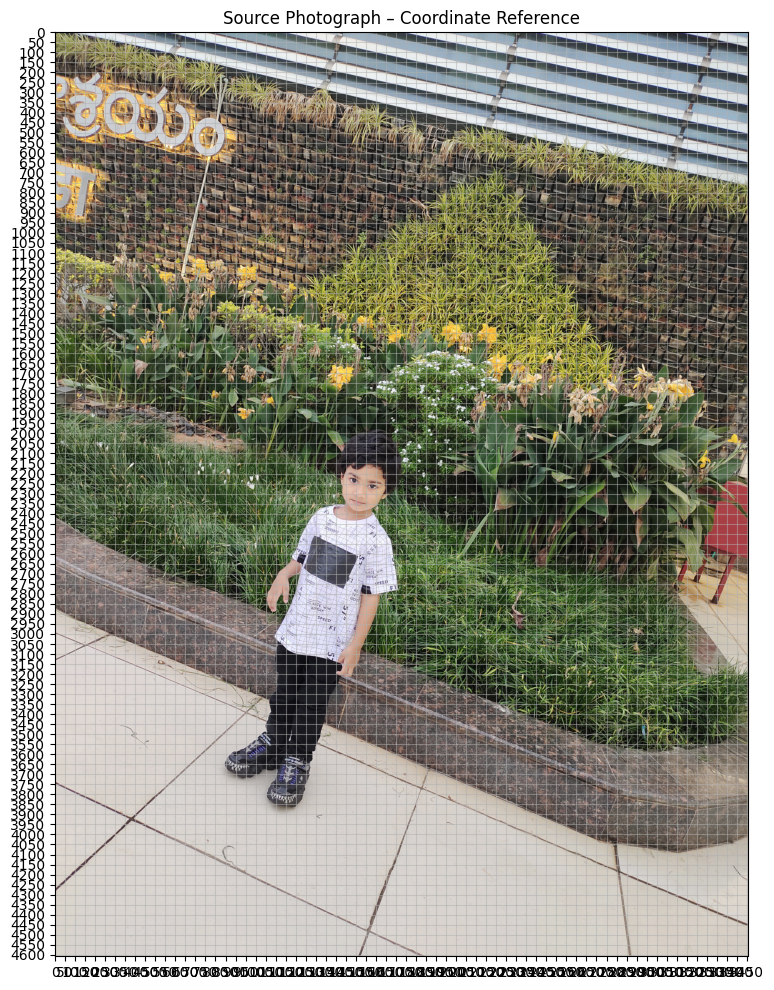

In [10]:

import matplotlib.pyplot as plt
import numpy as np

# Display the actual source photograph
source_array = np.array(source)

height, width = source_array.shape[:2]

print("Actual image width:", width)
print("Actual image height:", height)

plt.figure(figsize=(9, 12))
plt.imshow(source_array)

plt.xticks(np.arange(0, width, 50))
plt.yticks(np.arange(0, height, 50))

plt.grid(alpha=0.5)
plt.title("Source Photograph – Coordinate Reference")
plt.show()


Saving Analysis output 1 (3).png to Analysis output 1 (3) (1).png
Image dimensions: 407 x 708

========== FORENSIC RESULTS ==========
Suspected region: (260, 395, 375, 610)

ELA statistics:
Boy region mean: 3.182
Remaining image mean: 2.555

Noise statistics:
Boy region mean: 71.563
Remaining image mean: 58.884


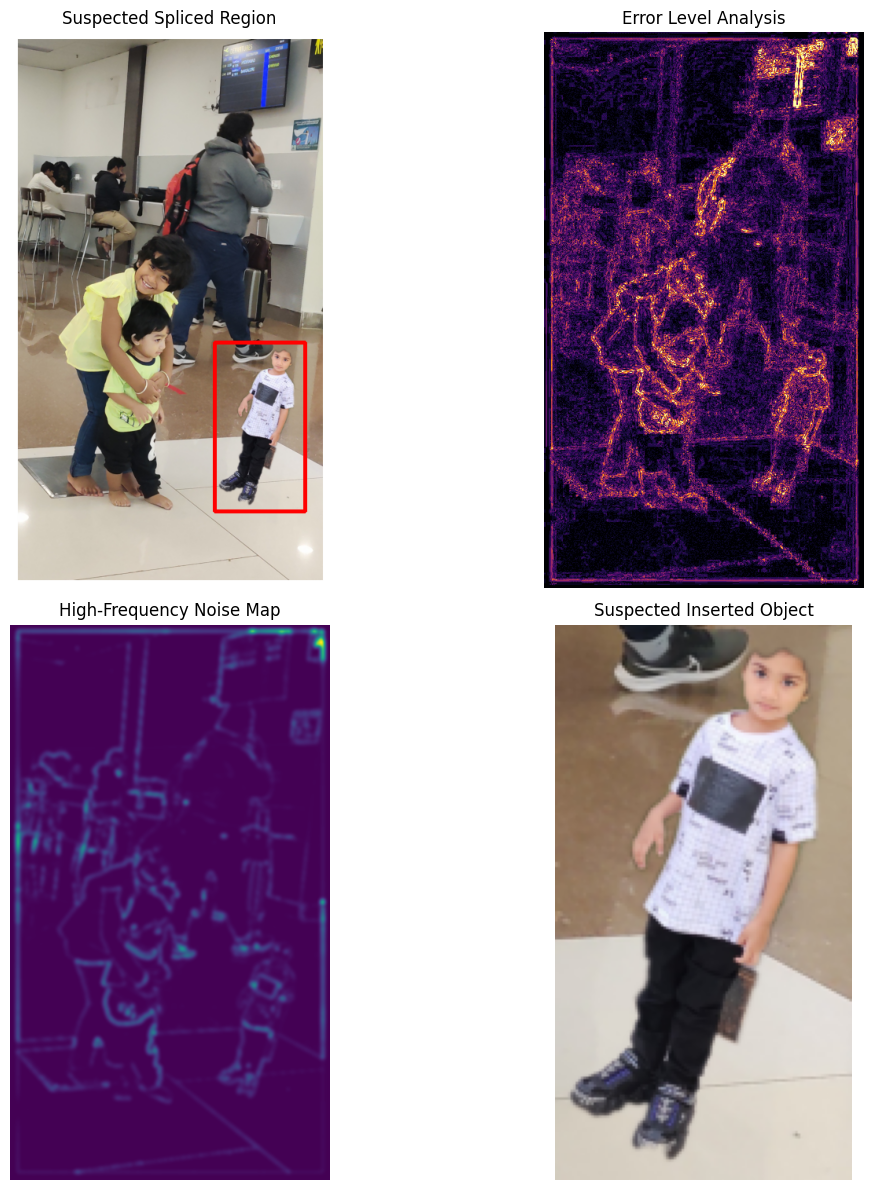


FORENSIC SCREENING COMPLETED


In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
import io

# ==========================================
# IMAGE SPLICING FORENSIC INVESTIGATION
# ==========================================

# 1. Upload manipulated photograph
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = Image.open(filename).convert("RGB")
image = np.array(img)

h, w = image.shape[:2]

print("Image dimensions:", w, "x", h)

# 2. Define suspected inserted region
# Coordinates based on your uploaded photograph (407 x 708)

x1 = int(w * 260 / 407)
y1 = int(h * 395 / 708)
x2 = int(w * 375 / 407)
y2 = int(h * 610 / 708)

suspect = image[y1:y2, x1:x2]

# ==========================================
# TECHNIQUE 1: ERROR LEVEL ANALYSIS
# ==========================================

buffer = io.BytesIO()

img.save(buffer, format="JPEG", quality=90)
buffer.seek(0)

recompressed = np.array(
    Image.open(buffer).convert("RGB")
)

ela = np.abs(
    image.astype(np.int16) -
    recompressed.astype(np.int16)
)

ela_gray = np.max(ela, axis=2)

# Enhance for visual examination
scale = np.percentile(ela_gray, 99.5)

ela_display = np.clip(
    ela_gray * 255 / max(scale, 1),
    0, 255
).astype(np.uint8)

# ==========================================
# TECHNIQUE 2: HIGH-FREQUENCY NOISE ANALYSIS
# ==========================================

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Remove low-frequency image structure
blur = cv2.GaussianBlur(gray, (5, 5), 0)

residual = cv2.absdiff(gray, blur)

# Local noise energy
noise_map = cv2.GaussianBlur(
    residual.astype(np.float32)**2,
    (15, 15), 0
)

noise_display = cv2.normalize(
    noise_map, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# ==========================================
# TECHNIQUE 3: SUSPECT REGION ANALYSIS
# ==========================================

roi_ela = ela_gray[y1:y2, x1:x2]
roi_noise = noise_map[y1:y2, x1:x2]

# Reference region: surrounding airport background
background_mask = np.ones((h, w), dtype=bool)
background_mask[y1:y2, x1:x2] = False

background_ela = ela_gray[background_mask]
background_noise = noise_map[background_mask]

print("\n========== FORENSIC RESULTS ==========")

print("Suspected region:", (x1, y1, x2, y2))

print("\nELA statistics:")
print("Boy region mean:", round(float(roi_ela.mean()), 3))
print("Remaining image mean:",
      round(float(background_ela.mean()), 3))

print("\nNoise statistics:")
print("Boy region mean:", round(float(roi_noise.mean()), 3))
print("Remaining image mean:",
      round(float(background_noise.mean()), 3))

# ==========================================
# DISPLAY FORENSIC RESULTS
# ==========================================

marked = image.copy()

cv2.rectangle(
    marked,
    (x1, y1), (x2, y2),
    (255, 0, 0), 3
)

fig, ax = plt.subplots(2, 2, figsize=(13, 12))

ax[0,0].imshow(marked)
ax[0,0].set_title("Suspected Spliced Region")

ax[0,1].imshow(ela_display, cmap="inferno")
ax[0,1].set_title("Error Level Analysis")

ax[1,0].imshow(noise_display, cmap="viridis")
ax[1,0].set_title("High-Frequency Noise Map")

ax[1,1].imshow(suspect)
ax[1,1].set_title("Suspected Inserted Object")

for a in ax.flat:
    a.axis("off")

plt.tight_layout()
plt.show()

print("\nFORENSIC SCREENING COMPLETED")
